In [ ]:
import pandas as pd
import pooch
from scipy.ndimage import median_filter as md

# Belhaven, NC water level from SECOORA ERDDAP (CSV; row 2 holds units).
# pooch caches the file in the OS cache dir (e.g. ~/.cache/ioos_qc), not in the repo.
url = (
    "https://erddap.secoora.org/erddap/tabledap/belhaven-nc.csv"
    "?time%2Cwater_surface_above_navd88%2Cwater_surface_above_navd88_qc_agg%2Cz"
    "&time%3E%3D2024-03-06T20%3A18%3A15Z&time%3C%3D2026-11-17T20%3A24%3A00Z"
)
known_hash="sha256:9ec8f78ae59a611da71d1fe4ed62446f1442daf628777f63507d7018a995a1c9"
fname = pooch.retrieve(
    url,
    known_hash=known_hash,  # ERDDAP regenerates the CSV, so its hash can change if the data are re-QC'd
    fname="belhaven-nc.csv",
    path=pooch.os_cache("ioos_qc"),
)
df = pd.read_csv(fname, skiprows=[1], parse_dates=["time"])

water_level = df["water_surface_above_navd88"].to_numpy()        # metres, NAVD88
time = df["time"].dt.tz_convert("UTC").dt.tz_localize(None)      # pandas Series, tz-naive UTC
existing_qc = df["water_surface_above_navd88_qc_agg"].to_numpy() # aggregate QARTOD flags (1/3/4)
water_level2 = md(water_level, size=3)

SHA256 hash of downloaded file: 9ec8f78ae59a611da71d1fe4ed62446f1442daf628777f63507d7018a995a1c9
Use this value as the 'known_hash' argument of 'pooch.retrieve' to ensure that the file hasn't changed if it is downloaded again in the future.


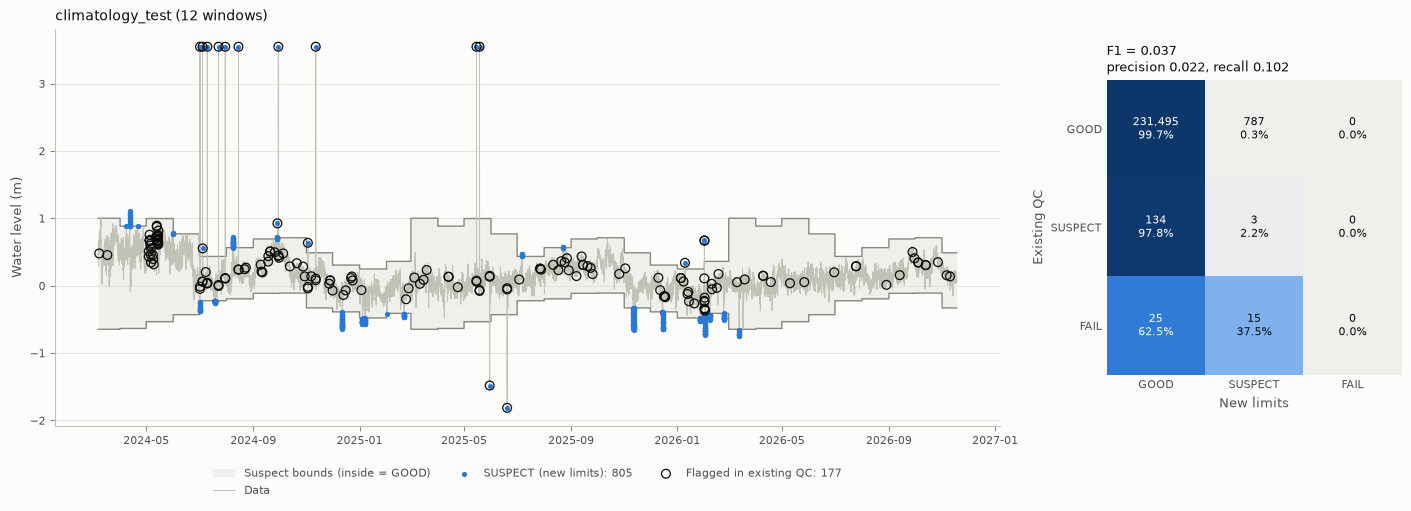

In [2]:
from ioos_qc import qartod
from ioos_qc.auto_limits import auto_climatology, auto_thresh, find_regimes
from ioos_qc.plotting import plot_limits
from ioos_qc.utils import compare_flags

# Gross range: suspect from the data, fail from the manufacturer/experts
suspect = auto_thresh(water_level, n_std=3)
flags = qartod.gross_range_test(water_level, fail_span=(-3.0, 4.0), suspect_span=suspect)

# What regimes are in the record?
# find_regimes(water_level, time, method="segments", n_regimes=14)
find_regimes(water_level2, time, method="seasonal", period="month")

# Climatology config from those regimes
# cfg = auto_climatology(water_level, time, method="segments", n_regimes=8, n_std=4,
#                          fail_span=(-3.0, 4.0))
cfg = auto_climatology(water_level2, time, method="seasonal", period="month", n_std = 4, n_regimes=366)
cfg = auto_climatology(water_level2, time)

flags = qartod.climatology_test(cfg, water_level, time)

# Compare with existing QC and plot
compare_flags(existing_qc, flags)["f1"]
fig = plot_limits(water_level, time, cfg, reference=existing_qc, ylabel="Water level (m)")


In [3]:
cfg

[{'tspan': (1, 1),
  'period': 'month',
  'vspan': (-0.47870105835148985, 0.24813251093740457)},
 {'tspan': (2, 2),
  'period': 'month',
  'vspan': (-0.4110174226640581, 0.3607565185049261)},
 {'tspan': (3, 3),
  'period': 'month',
  'vspan': (-0.6467754102992632, 1.0017030940076428)},
 {'tspan': (4, 4),
  'period': 'month',
  'vspan': (-0.6347818266907556, 0.8845660376550747)},
 {'tspan': (5, 5),
  'period': 'month',
  'vspan': (-0.533803975953587, 0.9971743939278445)},
 {'tspan': (6, 6),
  'period': 'month',
  'vspan': (-0.430220282815025, 0.7689400948905669)},
 {'tspan': (7, 7),
  'period': 'month',
  'vspan': (-0.22331092187309665, 0.4344872552514082)},
 {'tspan': (8, 8),
  'period': 'month',
  'vspan': (-0.1952789661995045, 0.5651792629112509)},
 {'tspan': (9, 9),
  'period': 'month',
  'vspan': (-0.11284882571823246, 0.6939243993203981)},
 {'tspan': (10, 10),
  'period': 'month',
  'vspan': (-0.10960705727641018, 0.7120092914400789)},
 {'tspan': (11, 11),
  'period': 'month',
  '